**Credit Card Fraud Detection using Machine Learning**

Machine Learning Internship Project



***Project Overview:-***

Credit card fraud has become one of the most significant challenges faced by financial institutions due to the increasing use of online transactions and digital payment systems. Fraudulent activities not only result in financial losses but also reduce customer trust and security. Therefore, developing an intelligent system that can accurately detect fraudulent transactions is essential.

***Problem Statement :-***

The objective of this project is to develop a machine learning model capable of accurately identifying fraudulent credit card transactions using historical transaction data. The model should effectively distinguish between genuine and fraudulent transactions, helping financial institutions reduce fraud-related losses while minimizing false alarms.

***Algorithms Used :-***

The following machine learning algorithms are implemented and compared:
1. Logistic Regression

2. Decision Tree Classifier

3. Random Forest Classifier

***Evaluation Metrics***

The performance of each model is evaluated using:

1. Accuracy

2. Precision

3. Recall

4. F1-Score

5. Confusion Matrix

6. Cross Validation

In [1]:
from google.colab import files
uploaded = files.upload()

Saving credit_card.csv to credit_card.csv


**Importing Libraries :-**

The following libraries are imported for data manipulation, visualization, preprocessing, model building, and performance evaluation.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

**Loading Dataset :-**



In [3]:
df = pd.read_csv("credit_card.csv")

**Displaying First Rows :-**



In [4]:
df.head()

,actionnr,merchant_id,average_amount_transaction_day,transaction_amount,is_declined,total_number_of_declines_day,isforeigntransaction,ishighriskcountry,daily_chargeback_avg_amt,sixmonth_avg_chbk_amt,sixmonth_chbk_freq,isfradulent
0,1,3160040998,100.0,3000.0,N,5,Y,Y,0,0.0,0,Y
1,2,3160040998,100.0,4300.0,N,5,Y,Y,0,0.0,0,Y
2,3,3160041896,185.5,4823.0,Y,5,N,N,0,0.0,0,Y
3,4,3160141996,185.5,5008.5,Y,8,N,N,0,0.0,0,Y
4,5,3160241992,500.0,26000.0,N,0,Y,Y,800,677.2,6,Y


**Shape of the dataset :-**



In [5]:
df.shape

(3075, 12)

**Column Names :-**


In [6]:
df.columns

Index(['actionnr', 'merchant_id', 'average_amount_transaction_day',
       'transaction_amount', 'is_declined', 'total_number_of_declines_day',
       'isforeigntransaction', 'ishighriskcountry', 'daily_chargeback_avg_amt',
       'sixmonth_avg_chbk_amt', 'sixmonth_chbk_freq', 'isfradulent'],
      dtype='object')

**Dataset Information:-**

The `info()` function provides details about each column, including data type, number of non-null values, and memory usage.

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3075 entries, 0 to 3074
Data columns (total 12 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   actionnr                        3075 non-null   int64  
 1   merchant_id                     3075 non-null   int64  
 2   average_amount_transaction_day  3075 non-null   float64
 3   transaction_amount              3075 non-null   float64
 4   is_declined                     3075 non-null   object 
 5   total_number_of_declines_day    3075 non-null   int64  
 6   isforeigntransaction            3075 non-null   object 
 7   ishighriskcountry               3075 non-null   object 
 8   daily_chargeback_avg_amt        3075 non-null   int64  
 9   sixmonth_avg_chbk_amt           3075 non-null   float64
 10  sixmonth_chbk_freq              3075 non-null   int64  
 11  isfradulent                     3075 non-null   object 
dtypes: float64(3), int64(5), object(4)

**Statistical Summary:-**

In [8]:
df.describe()

,actionnr,merchant_id,average_amount_transaction_day,transaction_amount,total_number_of_declines_day,daily_chargeback_avg_amt,sixmonth_avg_chbk_amt,sixmonth_chbk_freq
count,3075.000000,3.075000e+03,3075.000000,3075.000000,3075.000000,3075.000000,3075.000000,3075.000000
mean,1538.000000,5.026634e+09,515.026556,9876.399210,0.957398,55.737561,40.022407,0.391870
std,887.820365,9.870778e+08,291.906978,10135.331016,2.192391,206.634779,155.968840,1.548479
min,1.000000,3.160041e+09,4.011527,0.000000,0.000000,0.000000,0.000000,0.000000
25%,769.500000,4.170814e+09,269.788047,2408.781147,0.000000,0.000000,0.000000,0.000000
50%,1538.000000,5.025578e+09,502.549575,6698.891856,0.000000,0.000000,0.000000,0.000000
75%,2306.500000,5.889625e+09,765.272803,14422.568935,0.000000,0.000000,0.000000,0.000000
max,3075.000000,6.665906e+09,2000.000000,108000.000000,20.000000,998.000000,998.000000,9.000000


**Checking Missing Values :-**

In [9]:
df.isnull().sum()

,0
actionnr,0
merchant_id,0
average_amount_transaction_day,0
transaction_amount,0
is_declined,0
total_number_of_declines_day,0
isforeigntransaction,0
ishighriskcountry,0
daily_chargeback_avg_amt,0
sixmonth_avg_chbk_amt,0


**Checking Duplicate Rows :-**

In [10]:
df.duplicated().sum()

np.int64(0)

**Target Variable Distribution :-**

In [11]:
df["isfradulent"].value_counts()

,count
isfradulent,
N,2627
Y,448


**Making a Copy of the Dataset :-**

In [12]:
df_copy = df.copy()

**Removing Unnecessary Columns :-**

In [13]:
df.drop("actionnr", axis=1, inplace=True)

**Checking Data Types Again :-**

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3075 entries, 0 to 3074
Data columns (total 11 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   merchant_id                     3075 non-null   int64  
 1   average_amount_transaction_day  3075 non-null   float64
 2   transaction_amount              3075 non-null   float64
 3   is_declined                     3075 non-null   object 
 4   total_number_of_declines_day    3075 non-null   int64  
 5   isforeigntransaction            3075 non-null   object 
 6   ishighriskcountry               3075 non-null   object 
 7   daily_chargeback_avg_amt        3075 non-null   int64  
 8   sixmonth_avg_chbk_amt           3075 non-null   float64
 9   sixmonth_chbk_freq              3075 non-null   int64  
 10  isfradulent                     3075 non-null   object 
dtypes: float64(3), int64(4), object(4)
memory usage: 264.4+ KB


**Encoding the Dataset (Converting categorical columns into numerical values )**

In [15]:
df["is_declined"].unique()
df["isforeigntransaction"].unique()
df["ishighriskcountry"].unique()
df["isfradulent"].unique()

array(['Y', 'N'], dtype=object)

In [16]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df["is_declined"] = le.fit_transform(df["is_declined"])
df["isforeigntransaction"] = le.fit_transform(df["isforeigntransaction"])
df["ishighriskcountry"] = le.fit_transform(df["ishighriskcountry"])
df["isfradulent"] = le.fit_transform(df["isfradulent"])

**Verifying Encoding:-**

In [17]:
df.head()

,merchant_id,average_amount_transaction_day,transaction_amount,is_declined,total_number_of_declines_day,isforeigntransaction,ishighriskcountry,daily_chargeback_avg_amt,sixmonth_avg_chbk_amt,sixmonth_chbk_freq,isfradulent
0,3160040998,100.0,3000.0,0,5,1,1,0,0.0,0,1
1,3160040998,100.0,4300.0,0,5,1,1,0,0.0,0,1
2,3160041896,185.5,4823.0,1,5,0,0,0,0.0,0,1
3,3160141996,185.5,5008.5,1,8,0,0,0,0.0,0,1
4,3160241992,500.0,26000.0,0,0,1,1,800,677.2,6,1


**Checking Data Types Again :-**





In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3075 entries, 0 to 3074
Data columns (total 11 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   merchant_id                     3075 non-null   int64  
 1   average_amount_transaction_day  3075 non-null   float64
 2   transaction_amount              3075 non-null   float64
 3   is_declined                     3075 non-null   int64  
 4   total_number_of_declines_day    3075 non-null   int64  
 5   isforeigntransaction            3075 non-null   int64  
 6   ishighriskcountry               3075 non-null   int64  
 7   daily_chargeback_avg_amt        3075 non-null   int64  
 8   sixmonth_avg_chbk_amt           3075 non-null   float64
 9   sixmonth_chbk_freq              3075 non-null   int64  
 10  isfradulent                     3075 non-null   int64  
dtypes: float64(3), int64(8)
memory usage: 264.4 KB


**Separating Features and Target :-**

In [19]:
X = df.drop("isfradulent", axis=1)
y = df["isfradulent"]

**Checking Shapes :-**

In [20]:
X.shape

(3075, 10)

In [21]:
y.shape

(3075,)

In [22]:
X.head()

,merchant_id,average_amount_transaction_day,transaction_amount,is_declined,total_number_of_declines_day,isforeigntransaction,ishighriskcountry,daily_chargeback_avg_amt,sixmonth_avg_chbk_amt,sixmonth_chbk_freq
0,3160040998,100.0,3000.0,0,5,1,1,0,0.0,0
1,3160040998,100.0,4300.0,0,5,1,1,0,0.0,0
2,3160041896,185.5,4823.0,1,5,0,0,0,0.0,0
3,3160141996,185.5,5008.5,1,8,0,0,0,0.0,0
4,3160241992,500.0,26000.0,0,0,1,1,800,677.2,6


In [23]:
y.head()

,isfradulent
0,1
1,1
2,1
3,1
4,1


**Exploratory Data Analysis (EDA)**

**Visualize Fraud Distribution :-**

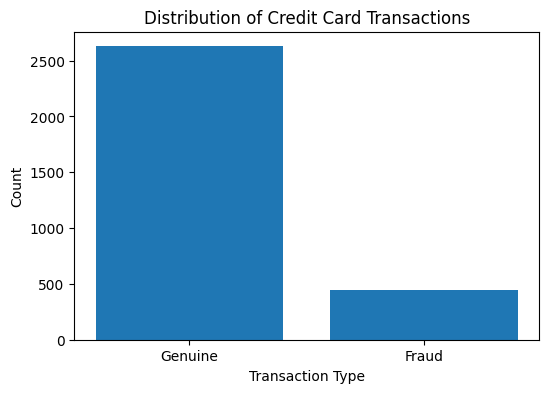

In [24]:
fraud_counts = df["isfradulent"].value_counts()
plt.figure(figsize=(6,4))
plt.bar(["Genuine","Fraud"], fraud_counts)
plt.title("Distribution of Credit Card Transactions")
plt.xlabel("Transaction Type")
plt.ylabel("Count")
plt.show()

**Transaction Amount Analysis:-**

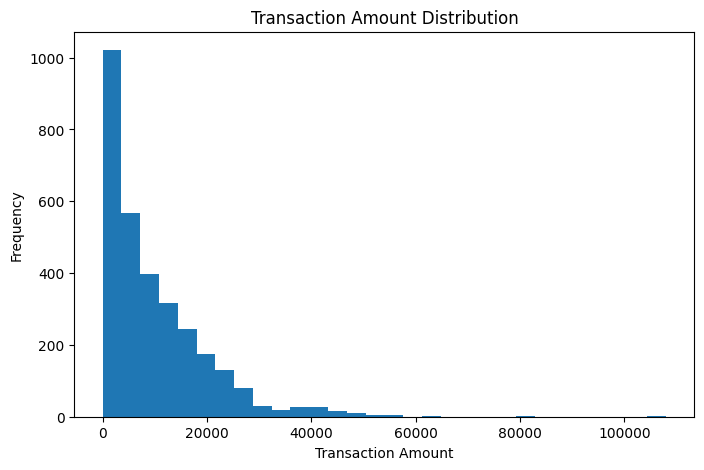

In [25]:
plt.figure(figsize=(8,5))
plt.hist(df["transaction_amount"], bins=30)
plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")
plt.show()

**Basic Statistics:-**

In [26]:
df["transaction_amount"].describe()

,transaction_amount
count,3075.000000
mean,9876.399210
std,10135.331016
min,0.000000
25%,2408.781147
50%,6698.891856
75%,14422.568935
max,108000.000000


**Fraud vs Transaction Amount :-**

/tmp/ipykernel_1750/999259760.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


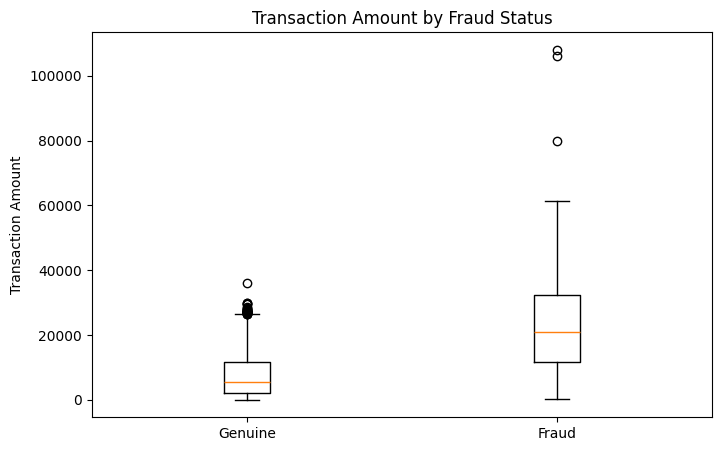

In [27]:
plt.figure(figsize=(8,5))

plt.boxplot(
    [ df[df["isfradulent"] == 0]["transaction_amount"], df[df["isfradulent"] == 1]["transaction_amount"]],labels=["Genuine", "Fraud"])
plt.title("Transaction Amount by Fraud Status")
plt.ylabel("Transaction Amount")
plt.show()

**Correlation :-**

In [28]:
correlation = df.corr(numeric_only=True)
correlation

,merchant_id,average_amount_transaction_day,transaction_amount,is_declined,total_number_of_declines_day,isforeigntransaction,ishighriskcountry,daily_chargeback_avg_amt,sixmonth_avg_chbk_amt,sixmonth_chbk_freq,isfradulent
merchant_id,1.000000,0.018223,0.046065,0.159211,-0.016165,0.030289,0.028611,0.088802,0.091621,0.118599,0.043068
average_amount_transaction_day,0.018223,1.000000,0.587111,0.081184,-0.009682,0.047316,0.014604,0.060429,0.060284,0.071849,0.023504
transaction_amount,0.046065,0.587111,1.000000,0.197009,0.259309,0.276764,0.325397,0.252298,0.259663,0.297623,0.528913
is_declined,0.159211,0.081184,0.197009,1.000000,0.115961,0.079761,0.127586,0.394083,0.407917,0.499365,0.271282
total_number_of_declines_day,-0.016165,-0.009682,0.259309,0.115961,1.000000,0.227904,0.292459,0.094834,0.081138,0.085028,0.531990
isforeigntransaction,0.030289,0.047316,0.276764,0.079761,0.227904,1.000000,0.489572,0.054798,0.060566,0.077083,0.478113
ishighriskcountry,0.028611,0.014604,0.325397,0.127586,0.292459,0.489572,1.000000,0.074902,0.073167,0.098241,0.639792
daily_chargeback_avg_amt,0.088802,0.060429,0.252298,0.394083,0.094834,0.054798,0.074902,1.000000,0.953663,0.884611,0.385964
sixmonth_avg_chbk_amt,0.091621,0.060284,0.259663,0.407917,0.081138,0.060566,0.073167,0.953663,1.000000,0.851339,0.375758
sixmonth_chbk_freq,0.118599,0.071849,0.297623,0.499365,0.085028,0.077083,0.098241,0.884611,0.851339,1.000000,0.443824


***Observations:-***

**Fraud Distribution**

1. Genuine transactions are much more frequent than fraud transactions.

2. The dataset is imbalanced.

3. Accuracy alone will not be sufficient.

**Transaction Amount**

1. Most transactions are low to medium value.

2. A few transactions have very high amounts.

3. Outliers are present.

**Fraud vs Amount**

1. Fraudulent transactions tend to have higher transaction amounts than genuine transactions.


***Foreign Transaction vs Fraud:-***

In [29]:
foreign_fraud = pd.crosstab(
    df["isforeigntransaction"],
    df["isfradulent"]
)
print(foreign_fraud)

isfradulent              0    1
isforeigntransaction           
0                     2242  127
1                      385  321


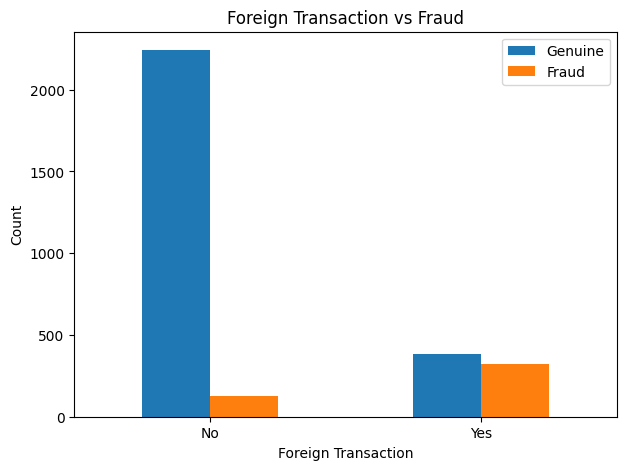

In [30]:
foreign_fraud.plot(kind="bar", figsize=(7,5))
plt.title("Foreign Transaction vs Fraud")
plt.xlabel("Foreign Transaction")
plt.ylabel("Count")
plt.xticks([0,1],["No","Yes"], rotation=0)
plt.legend(["Genuine","Fraud"])
plt.show()

***Observation:-***


Fraud occurs more frequently in foreign transactions than domestic ones.

**High-Risk Country vs Fraud :-**

In [31]:
risk_country = pd.crosstab(
    df["ishighriskcountry"],
    df["isfradulent"]
)
print(risk_country)

isfradulent           0    1
ishighriskcountry           
0                  2625  245
1                     2  203


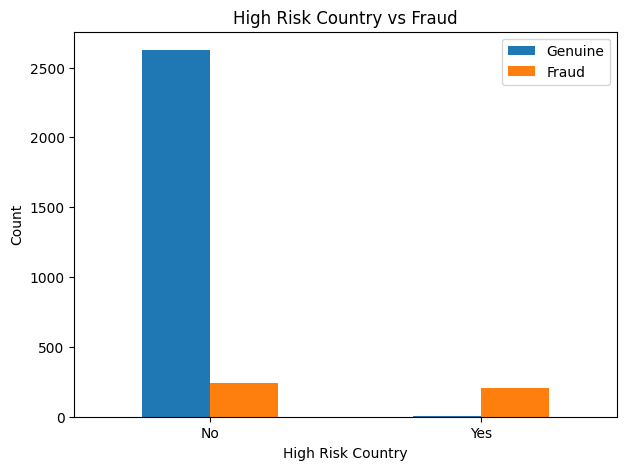

In [32]:
risk_country.plot(kind="bar", figsize=(7,5))
plt.title("High Risk Country vs Fraud")
plt.xlabel("High Risk Country")
plt.ylabel("Count")
plt.xticks([0,1],["No","Yes"], rotation=0)
plt.legend(["Genuine","Fraud"])
plt.show()

**Chargeback Analysis:-**

/tmp/ipykernel_1750/926630373.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


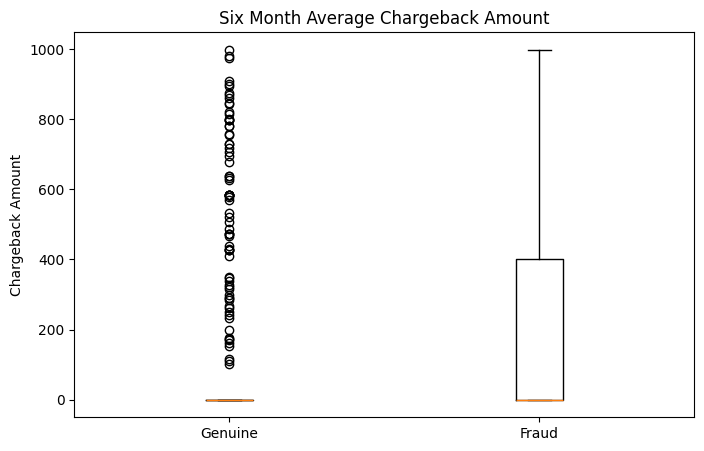

In [33]:
plt.figure(figsize=(8,5))
plt.boxplot(
[
df[df["isfradulent"]==0]["sixmonth_avg_chbk_amt"],
df[df["isfradulent"]==1]["sixmonth_avg_chbk_amt"]
],
labels=["Genuine","Fraud"]
)
plt.title("Six Month Average Chargeback Amount")
plt.ylabel("Chargeback Amount")
plt.show()

Genuine transactions have a very concentrated distribution of six-month average chargeback amounts, with most values close to zero. Fraudulent transactions show a much wider spread and higher chargeback amounts, indicating that historical chargeback behavior may be associated with fraudulent activity.

**Average Six Month Chargeback Amount :-**

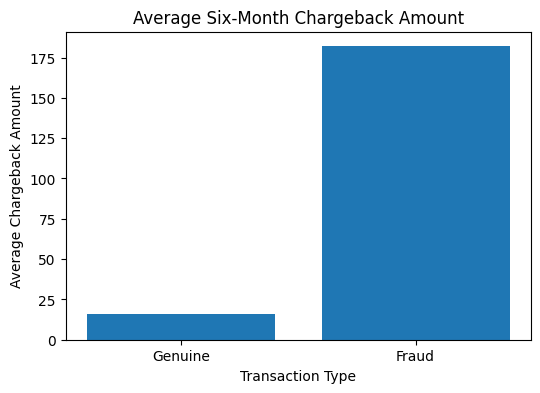

In [34]:
avg_chargeback = df.groupby("isfradulent")["sixmonth_avg_chbk_amt"].mean()
plt.figure(figsize=(6,4))
plt.bar(["Genuine", "Fraud"], avg_chargeback)
plt.title("Average Six-Month Chargeback Amount")
plt.xlabel("Transaction Type")
plt.ylabel("Average Chargeback Amount")
plt.show()

**Average Six-Month Chargeback Frequency :-**

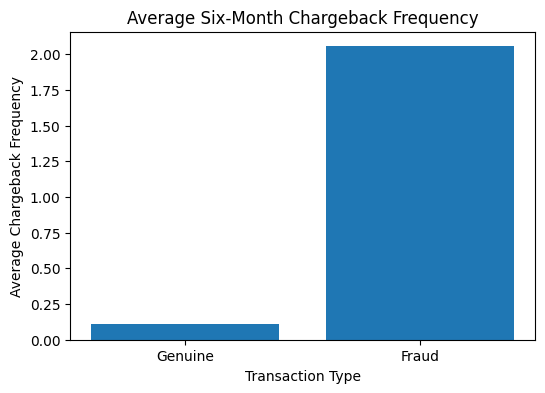

In [35]:
avg_freq = df.groupby("isfradulent")["sixmonth_chbk_freq"].mean()
plt.figure(figsize=(6,4))
plt.bar(["Genuine", "Fraud"], avg_freq)
plt.title("Average Six-Month Chargeback Frequency")
plt.xlabel("Transaction Type")
plt.ylabel("Average Chargeback Frequency")
plt.show()

**Correlation Heatmap :-**

In [36]:
import seaborn as sns

In [37]:
corr_matrix = df.corr(numeric_only=True)
corr_matrix

,merchant_id,average_amount_transaction_day,transaction_amount,is_declined,total_number_of_declines_day,isforeigntransaction,ishighriskcountry,daily_chargeback_avg_amt,sixmonth_avg_chbk_amt,sixmonth_chbk_freq,isfradulent
merchant_id,1.000000,0.018223,0.046065,0.159211,-0.016165,0.030289,0.028611,0.088802,0.091621,0.118599,0.043068
average_amount_transaction_day,0.018223,1.000000,0.587111,0.081184,-0.009682,0.047316,0.014604,0.060429,0.060284,0.071849,0.023504
transaction_amount,0.046065,0.587111,1.000000,0.197009,0.259309,0.276764,0.325397,0.252298,0.259663,0.297623,0.528913
is_declined,0.159211,0.081184,0.197009,1.000000,0.115961,0.079761,0.127586,0.394083,0.407917,0.499365,0.271282
total_number_of_declines_day,-0.016165,-0.009682,0.259309,0.115961,1.000000,0.227904,0.292459,0.094834,0.081138,0.085028,0.531990
isforeigntransaction,0.030289,0.047316,0.276764,0.079761,0.227904,1.000000,0.489572,0.054798,0.060566,0.077083,0.478113
ishighriskcountry,0.028611,0.014604,0.325397,0.127586,0.292459,0.489572,1.000000,0.074902,0.073167,0.098241,0.639792
daily_chargeback_avg_amt,0.088802,0.060429,0.252298,0.394083,0.094834,0.054798,0.074902,1.000000,0.953663,0.884611,0.385964
sixmonth_avg_chbk_amt,0.091621,0.060284,0.259663,0.407917,0.081138,0.060566,0.073167,0.953663,1.000000,0.851339,0.375758
sixmonth_chbk_freq,0.118599,0.071849,0.297623,0.499365,0.085028,0.077083,0.098241,0.884611,0.851339,1.000000,0.443824


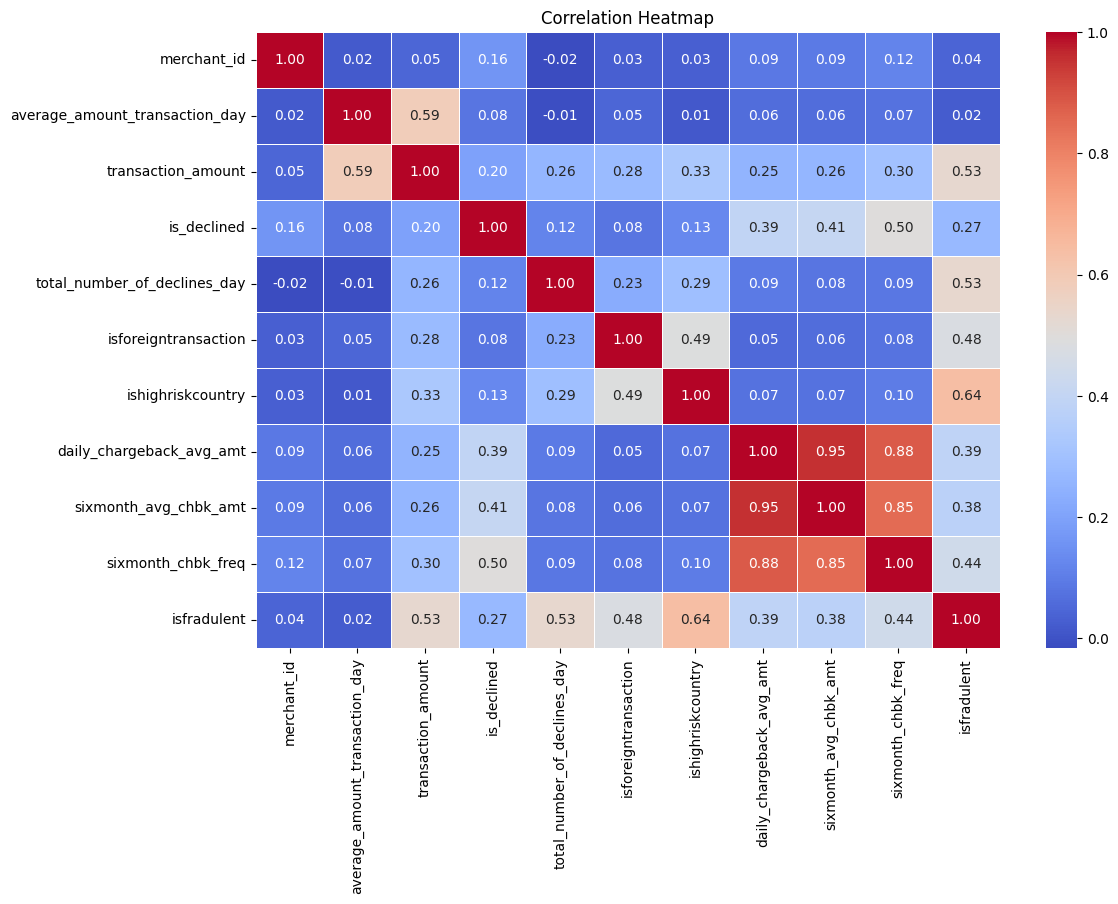

In [38]:
plt.figure(figsize=(12,8))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)
plt.title("Correlation Heatmap")
plt.show()

**Observations :-**

The correlation heatmap shows the relationships among numerical variables.

Transaction amount, high-risk country, and chargeback-related features exhibit stronger positive correlations with fraudulent transactions.

Merchant ID has little or no correlation with fraud, suggesting it contributes less to prediction.

Correlation helps identify potentially important features but does not imply causation.

**Train-Test Split & Feature Scaling :-**

In [39]:
from sklearn.model_selection import train_test_split

In [40]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [41]:
print(X_train.shape)

(2460, 10)


In [42]:
print(X_test.shape)

(615, 10)


In [43]:
print(y_train.shape)

(2460,)


In [44]:
print(y_test.shape)

(615,)


In [45]:
from sklearn.preprocessing import StandardScaler

In [46]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

**Logistic Regression :-**

In [47]:
from sklearn.linear_model import LogisticRegression
lr_model = LogisticRegression(random_state=42)
lr_model.fit(X_train_scaled, y_train)
y_pred_lr = lr_model.predict(X_test_scaled)

In [48]:
from sklearn.metrics import (accuracy_score,confusion_matrix,classification_report)

In [49]:
accuracy = accuracy_score(y_test, y_pred_lr)
print("Accuracy:", accuracy)

Accuracy: 0.9869918699186991


In [50]:
cm = confusion_matrix(y_test, y_pred_lr)
print(cm)

[[509   3]
 [  5  98]]


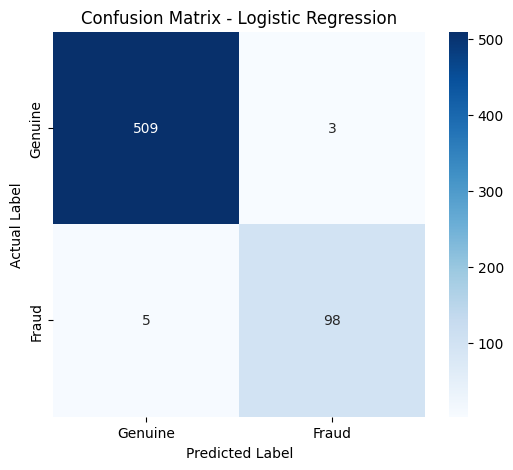

In [51]:
plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Genuine", "Fraud"],
    yticklabels=["Genuine", "Fraud"]
)
plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

***Observations :-***

The confusion matrix shows that the Logistic Regression model correctly classified most genuine and fraudulent transactions. A small number of genuine transactions were incorrectly classified as fraud (False Positives), while a few fraudulent transactions were missed (False Negatives). Since missing fraudulent transactions can result in financial loss, reducing False Negatives is particularly important in credit card fraud detection

In [52]:
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       512
           1       0.97      0.95      0.96       103

    accuracy                           0.99       615
   macro avg       0.98      0.97      0.98       615
weighted avg       0.99      0.99      0.99       615



**Decision Tree Classifier :-**

In [53]:
from sklearn.tree import DecisionTreeClassifier
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)

In [54]:
from sklearn.metrics import accuracy_score
accuracy_dt = accuracy_score(y_test, y_pred_dt)
print("Decision Tree Accuracy:", accuracy_dt)

Decision Tree Accuracy: 0.9691056910569106


In [55]:
from sklearn.metrics import confusion_matrix
cm_dt = confusion_matrix(y_test, y_pred_dt)
print(cm_dt)

[[503   9]
 [ 10  93]]


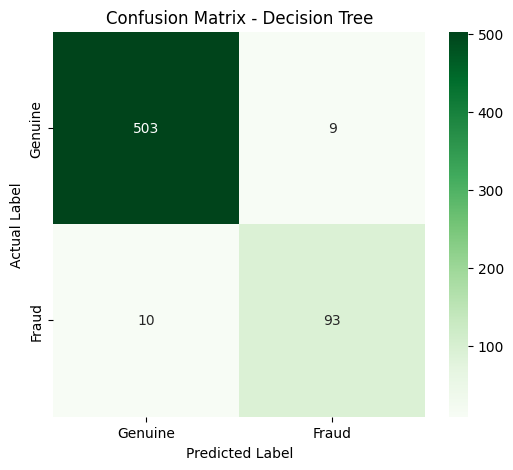

In [56]:
plt.figure(figsize=(6,5))
sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Genuine","Fraud"],
    yticklabels=["Genuine","Fraud"]
)
plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [57]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

           0       0.98      0.98      0.98       512
           1       0.91      0.90      0.91       103

    accuracy                           0.97       615
   macro avg       0.95      0.94      0.94       615
weighted avg       0.97      0.97      0.97       615



**Random Forest Classifier :-**

In [58]:
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier( n_estimators=100,  random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

In [59]:
from sklearn.metrics import accuracy_score
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print("Random Forest Accuracy:", accuracy_rf)

Random Forest Accuracy: 0.9804878048780488


In [60]:
from sklearn.metrics import confusion_matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)
print(cm_rf)

[[509   3]
 [  9  94]]


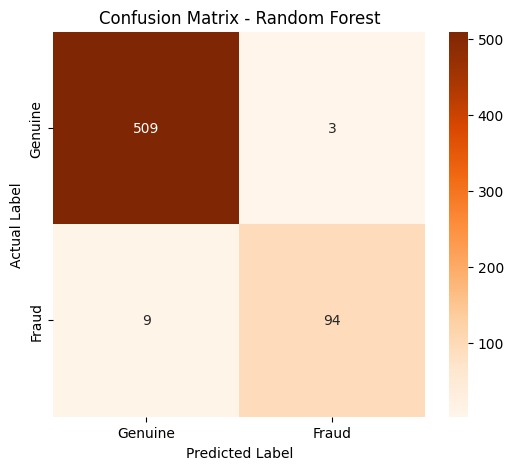

In [61]:
plt.figure(figsize=(6,5))
sns.heatmap( cm_rf, annot=True, fmt="d", cmap="Oranges", xticklabels=["Genuine","Fraud"],   yticklabels=["Genuine","Fraud"])
plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [62]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.98      0.99      0.99       512
           1       0.97      0.91      0.94       103

    accuracy                           0.98       615
   macro avg       0.98      0.95      0.96       615
weighted avg       0.98      0.98      0.98       615



In [63]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)
print(feature_importance)

                          Feature  Importance
6               ishighriskcountry    0.289298
2              transaction_amount    0.199303
4    total_number_of_declines_day    0.190737
9              sixmonth_chbk_freq    0.118661
1  average_amount_transaction_day    0.051986
8           sixmonth_avg_chbk_amt    0.042125
5            isforeigntransaction    0.040209
0                     merchant_id    0.031041
7        daily_chargeback_avg_amt    0.030940
3                     is_declined    0.005701


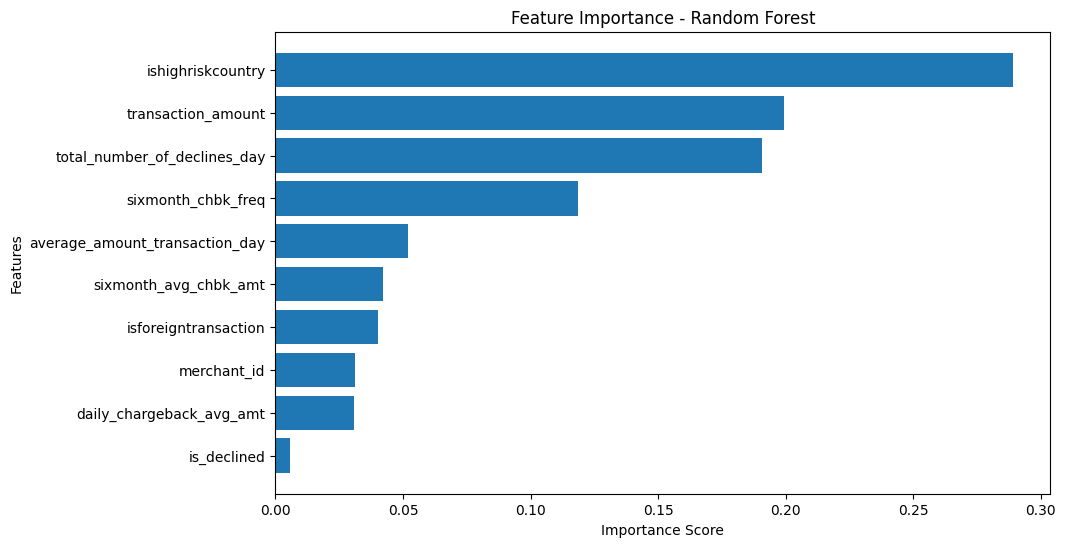

In [64]:
feature_importance = feature_importance.sort_values("Importance")
plt.figure(figsize=(10,6))
plt.barh(feature_importance["Feature"],feature_importance["Importance"])
plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.show()

***Observations :-***

The Random Forest model identified Transaction Amount as the most influential feature in detecting fraudulent transactions, while Declined Transactions contributed very little.

**Comparing Models :-**

In [65]:
from sklearn.metrics import precision_score, recall_score, f1_score
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_rf)
    ],
    "Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_rf)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_rf)
    ]
})
comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.986992,0.970297,0.951456,0.960784
1,Decision Tree,0.969106,0.911765,0.902913,0.907317
2,Random Forest,0.980488,0.969072,0.912621,0.940000


In [66]:
best_model = comparison.loc[
    comparison["Accuracy"].idxmax()
]
print(best_model)

Model        Logistic Regression
Accuracy                0.986992
Precision               0.970297
Recall                  0.951456
F1 Score                0.960784
Name: 0, dtype: object


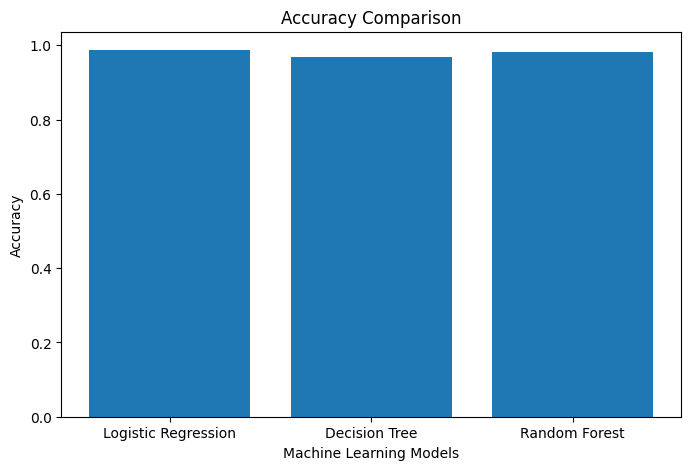

In [67]:
plt.figure(figsize=(8,5))
plt.bar(
    comparison["Model"],
    comparison["Accuracy"]
)
plt.title("Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")
plt.show()

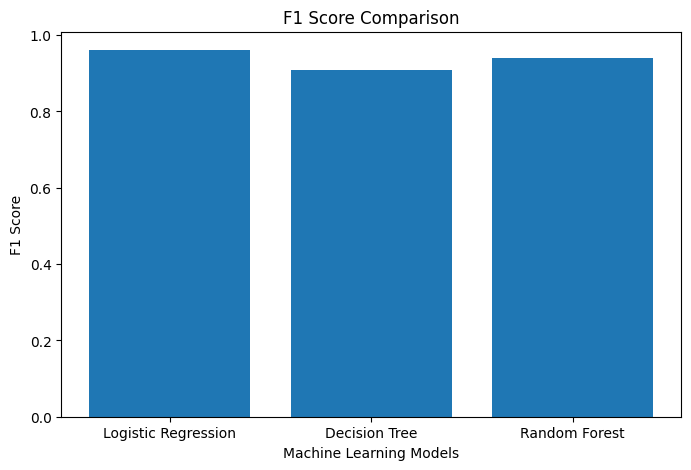

In [68]:
plt.figure(figsize=(8,5))
plt.bar(
    comparison["Model"],
    comparison["F1 Score"]
)
plt.title("F1 Score Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("F1 Score")
plt.show()

In [69]:
print(X.columns)

Index(['merchant_id', 'average_amount_transaction_day', 'transaction_amount',
       'is_declined', 'total_number_of_declines_day', 'isforeigntransaction',
       'ishighriskcountry', 'daily_chargeback_avg_amt',
       'sixmonth_avg_chbk_amt', 'sixmonth_chbk_freq'],
      dtype='object')


**Cross Validation :-**

***Logistic Regression***

In [70]:
from sklearn.model_selection import cross_val_score
cv_lr = cross_val_score(
    lr_model,
    X_train_scaled,
    y_train,
    cv=5
)
print(cv_lr)

[0.98373984 0.98577236 0.98577236 0.99186992 0.9898374 ]


In [71]:
print(cv_lr.mean())

0.9873983739837398


***Decision Tree***

In [72]:
cv_dt = cross_val_score(
    dt_model,
    X_train,
    y_train,
    cv=5
)
print(cv_dt.mean())

0.978048780487805


***Random Forest***

In [73]:
cv_rf = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=5
)
print(cv_rf.mean())

0.9792682926829268


***Observation :-***

Five-fold cross validation was performed to evaluate model stability. Logistic Regression achieved the highest average cross-validation accuracy, indicating better generalization compared to Random Forest and Decision Tree.

**Hyperparameter Tuning :-**

***Decision Tree***

In [74]:
from sklearn.model_selection import GridSearchCV

In [75]:
param_grid = {
    "max_depth": [3, 5, 7, 10],
    "min_samples_split": [2, 5, 10]
}

In [76]:
grid_dt = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring="accuracy"
)
grid_dt.fit(X_train, y_train)
print(grid_dt.best_params_)

{'max_depth': 10, 'min_samples_split': 5}


In [77]:
print(grid_dt.best_score_)

0.9821138211382113


In [78]:
best_dt = grid_dt.best_estimator_

***Random Forest***

In [79]:
param_grid_rf = {
    "n_estimators": [50, 100, 150],
    "max_depth": [5, 10, None],
    "min_samples_split": [2, 5]
}

In [80]:
grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid_rf,
    cv=5,
    scoring="accuracy"
)
grid_rf.fit(X_train, y_train)
print(grid_rf.best_params_)
best_rf = grid_rf.best_estimator_
print (best_rf)

{'max_depth': None, 'min_samples_split': 5, 'n_estimators': 150}
RandomForestClassifier(min_samples_split=5, n_estimators=150, random_state=42)


***Logistic Regression***

In [81]:
from sklearn.model_selection import GridSearchCV
param_lr = {
    "C": [0.1, 1, 10]
}
grid_lr = GridSearchCV( LogisticRegression(random_state=42), param_lr, cv=5, scoring="accuracy")
grid_lr.fit(X_train_scaled, y_train)

GridSearchCV(cv=5, estimator=LogisticRegression(random_state=42),
             param_grid={'C': [0.1, 1, 10]}, scoring='accuracy')

In [82]:
print(grid_lr.best_params_)

{'C': 10}


In [83]:
best_lr = grid_lr.best_estimator_

In [84]:
y_pred_lr = best_lr.predict(X_test_scaled)

In [85]:
from sklearn.metrics import accuracy_score
print("Accuracy:", accuracy_score(y_test, y_pred_lr))

Accuracy: 0.9886178861788618


In [86]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
y_pred_lr = best_lr.predict(X_test_scaled)
print(" Logistic Regression After Hyperparameter Tuning ")
print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Classification Report:")
print(classification_report(y_test, y_pred_lr))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

 Logistic Regression After Hyperparameter Tuning 
Accuracy: 0.9886178861788618
Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       512
           1       0.98      0.95      0.97       103

    accuracy                           0.99       615
   macro avg       0.99      0.97      0.98       615
weighted avg       0.99      0.99      0.99       615

Confusion Matrix:
[[510   2]
 [  5  98]]


In [87]:
y_pred_dt = best_dt.predict(X_test)
print(" Decision Tree After Hyperparameter Tuning ")
print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Classification Report:")
print(classification_report(y_test, y_pred_dt))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

 Decision Tree After Hyperparameter Tuning 
Accuracy: 0.9691056910569106
Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.98       512
           1       0.93      0.88      0.91       103

    accuracy                           0.97       615
   macro avg       0.95      0.93      0.94       615
weighted avg       0.97      0.97      0.97       615

Confusion Matrix:
[[505   7]
 [ 12  91]]


In [88]:
y_pred_rf = best_rf.predict(X_test)
print("Random Forest After Hyperparameter Tuning ")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Classification Report:")
print(classification_report(y_test, y_pred_rf))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Random Forest After Hyperparameter Tuning 
Accuracy: 0.9804878048780488
Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.99       512
           1       0.97      0.91      0.94       103

    accuracy                           0.98       615
   macro avg       0.98      0.95      0.96       615
weighted avg       0.98      0.98      0.98       615

Confusion Matrix:
[[509   3]
 [  9  94]]


In [89]:
import pandas as pd
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree", "Random Forest"],
    "Accuracy Before Tuning": [98.70, 96.91, 98.05],
    "Accuracy After Tuning": [
        accuracy_score(y_test, y_pred_lr) * 100,
        accuracy_score(y_test, y_pred_dt) * 100,
        accuracy_score(y_test, y_pred_rf) * 100
    ]
})
comparison

,Model,Accuracy Before Tuning,Accuracy After Tuning
0,Logistic Regression,98.70,98.861789
1,Decision Tree,96.91,96.910569
2,Random Forest,98.05,98.048780


**Best Model Selection :-**

Based on the comparison of Accuracy, Precision, Recall and F1-Score, Logistic Regression achieved the best overall performance. Therefore, Logistic Regression was selected as the final model for fraud detection.

**Prediction System (Final Model) :-**

In [90]:
import pandas as pd
new_transaction = pd.DataFrame({
    'merchant_id': [25],
    'average_amount_transaction_day': [4500],
    'transaction_amount': [7000],
    'is_declined': [5],
    'total_number_of_declines_day': [1],
    'isforeigntransaction': [0],
    'ishighriskcountry': [1],
    'daily_chargeback_avg_amt': [0],
    'sixmonth_avg_chbk_amt': [1500],
    'sixmonth_chbk_freq': [1]
})

In [91]:
new_transaction_scaled = scaler.transform(new_transaction)

In [92]:
prediction = best_lr.predict(new_transaction_scaled)

In [93]:
if prediction[0] == 1:
    print(" Fraudulent Transaction")
else:
    print(" Genuine Transaction")

 Genuine Transaction


In [94]:
probability = best_lr.predict_proba(new_transaction_scaled)
print("Probability of Genuine Transaction :", round(probability[0][0]*100, 2), "%")
print("Probability of Fraudulent Transaction:", round(probability[0][1]*100, 2), "%")
if prediction[0] == 1:
    print("Prediction: Fraudulent Transaction")
else:
    print("Prediction: Genuine Transaction")

Probability of Genuine Transaction : 100.0 %
Probability of Fraudulent Transaction: 0.0 %
Prediction: Genuine Transaction


The Logistic Regression model was used to predict whether a new transaction is genuine or fraudulent. Along with the predicted class, the system also displays the probability of each class, providing a confidence score for the prediction.

**Conclusion :-**

In this project, three machine learning models were developed and compared for credit card fraud detection.

After evaluating their performance using Accuracy, Precision, Recall, and F1-Score, Logistic Regression achieved the best overall performance.

Cross Validation and Hyperparameter Tuning were also performed to improve the reliability of the models.

Based on the final results, Logistic Regression was selected as the best model for detecting fraudulent credit card transactions.

**Future Scope:-**

- Test the model on larger and more diverse datasets.
- Improve the fraud prediction system by making it more user-friendly.
- Continue improving the model using more advanced feature engineering techniques.